In [301]:
import numpy as np
rng = np.random.default_rng()

import seaborn as sns
import matplotlib.pyplot as plt
import yaml
from pathlib import Path

In [302]:
par_file = Path(r"C:\Users\User\python_code\start_point\gapi_uti\data\jupyter_config.yaml")
with open(par_file, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

In [303]:
#risk_probabilities = np.array([1.0,0.0,0.0])  # the probability of being no risk, risky, risky + recent infection
risk_probabilities = np.array(cfg["risk_probabilities"])
risk_ratios = np.array(cfg["risk_ratios"])
risk_names = ["regular", "intermediate", "high"]
true_strain_probs = np.array(cfg["true_strain_probs"])
uti_prev = cfg["uti_prev"]

# to mix in an unobservable risk component
un_risk_prop = cfg["un_risk_prop"]

# generate patients
num_patients = cfg["num_patients"]
patients = []
uti_count = 0
strain_counts = np.array([0,0,0])

for i in range(0,num_patients):
    obs_risk_fac = risk_ratios[rng.choice(3, p=risk_probabilities)]
    #un_obs_risk = rng.uniform(low=1.0, high=2.0)
    un_obs_risk = min(1 + rng.exponential(scale=cfg["un_risk_exp_scale"]), 2)
    risk_fac = (1-un_risk_prop)*obs_risk_fac + un_risk_prop*un_obs_risk
    uti_prob = min(risk_fac*uti_prev, 1)
    uti_status=(rng.binomial(1,uti_prob)==1)
    patient_status = {"uti_status": uti_status, "uti_strain": None, "risk_factor": risk_fac}
    if uti_status:
        patient_status["uti_strain"] = rng.choice(3, p=true_strain_probs)
        uti_count += 1
        strain_counts[patient_status["uti_strain"]] += 1

    patients.append(patient_status)

print(f"True UTI prevalence: {uti_prev}")
print(f"Measured UTI prevalence: {uti_count/num_patients}\n")

print(f"True strain breakdown: {true_strain_probs}")
print(f"Strain breakdown: {strain_counts/uti_count}")

True UTI prevalence: 0.15
Measured UTI prevalence: 0.187

True strain breakdown: [0.5  0.35 0.15]
Strain breakdown: [0.49197861 0.34224599 0.1657754 ]


In [304]:
# define the capabilities of the diagnostics
phys_uti_prev = rng.beta(*cfg["phys_beta_pars"])  # total uti prevalence
phys_strain_probs = rng.dirichlet(cfg["phys_dir_pars"])  # first line susceptible, second line susceptible, total resistance
diag_sens_spec = cfg["diag_sens_spec"]
all_strategies = ["clinical", "dipstick", "urine_culture", "rapid_test", "rapid_plus_ast"]

# valid choices are clinical, dipstick, urine_culture, rapid_test, rapid_plus_ast
def diagnostic_output(patient_status, strategy="clinical"):
    # by default, there is no strain chosen
    strain_diagnosis = None

    # evaluate patient using chosen strategy
    if strategy == "clinical":
        uti_diagnosis = (1==rng.binomial(1, patient_status["risk_factor"]*phys_uti_prev))
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy in ["dipstick", "urine_culture", "rapid_test"]:
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec[strategy][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec[strategy][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy == "rapid_plus_ast":
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec["rapid_plus_ast"][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec["rapid_plus_ast"][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = patient_status["uti_strain"]  # what happens if this is a false positive??
    
    else:
        raise ValueError(f"Invalid diagnostic strategy: {strategy}")
    
    return uti_diagnosis, strain_diagnosis

In [305]:
conf_mat_dict = {}
for chosen_strategy in all_strategies:
    # to analyze the success rates of the strategies, we compute confusion matrices for both strain diagnosis
    # and whether the uti was detected in the first place, for each risk group
    strain_confusion_matrices = [np.zeros((len(true_strain_probs),len(true_strain_probs))) for _ in range(0,3)]
    uti_confusion_matrices = [np.zeros((2,2)) for _ in range(0,3)]
    overall_confusion_matrices = [np.zeros((1+len(true_strain_probs),1+len(true_strain_probs))) for _ in range(0,3)]

    for patient_status in patients:
        true_uti_status, true_strain, risk_factor = patient_status["uti_status"], patient_status["uti_strain"], patient_status["risk_factor"]
        patient_risk_status = int(np.flatnonzero(risk_ratios == risk_factor)[0])
        phys_uti_diag, phys_uti_strain = diagnostic_output(patient_status, strategy=chosen_strategy)

        if phys_uti_diag:
            total_phys_index = phys_uti_strain + 1
        else:
            total_phys_index = 0
        
        if true_uti_status:
            total_true_index = true_strain + 1
        else:
            total_true_index = 0
        overall_confusion_matrices[patient_risk_status][total_true_index, total_phys_index] += 1 

        # if physician has correctly determined there is a uti, check if they get the strain right
        if true_uti_status and phys_uti_diag:
            strain_confusion_matrices[patient_risk_status][true_strain, phys_uti_strain] += 1 

        true_uti_status = int(true_uti_status)
        phys_uti_status = int(phys_uti_diag)
        uti_confusion_matrices[patient_risk_status][true_uti_status, phys_uti_status] +=1

    for i in range(0,3):
        uti_confusion_matrices[i] = uti_confusion_matrices[i]/uti_confusion_matrices[i].sum()
        strain_confusion_matrices[i] = strain_confusion_matrices[i]/strain_confusion_matrices[i].sum()
        overall_confusion_matrices[i] = overall_confusion_matrices[i]/overall_confusion_matrices[i].sum()

    
    conf_mat_dict[chosen_strategy] = {"uti": uti_confusion_matrices, "strain": strain_confusion_matrices, "overall": overall_confusion_matrices}


In [306]:
chosen_strategy = "rapid_plus_ast"
uti_confusion_matrices = conf_mat_dict[chosen_strategy]["uti"]
strain_confusion_matrices = conf_mat_dict[chosen_strategy]["strain"]
overall_confusion_matrices = conf_mat_dict[chosen_strategy]["overall"]

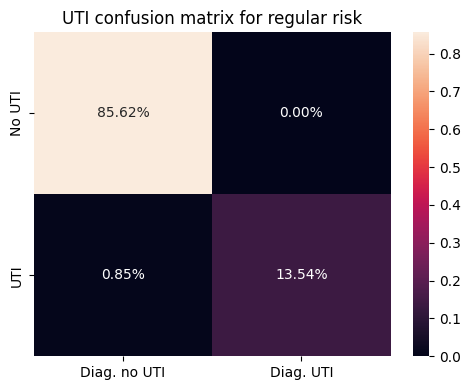

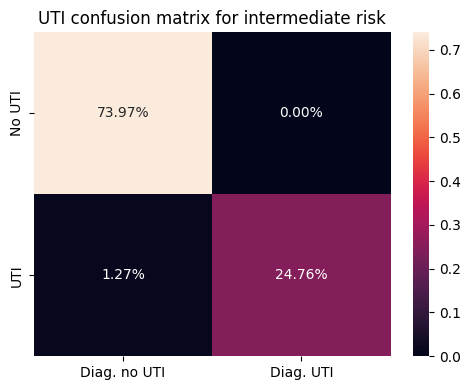

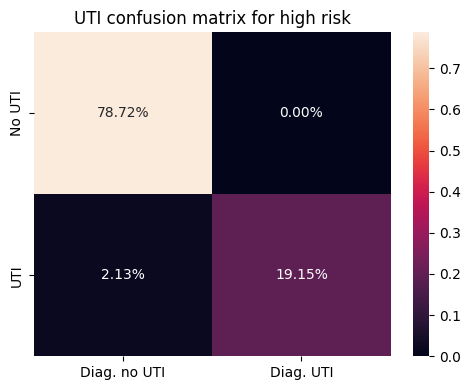

In [307]:

for i, matrix in enumerate(uti_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        normalized,
        yticklabels=["No UTI", "UTI"],
        xticklabels=["Diag. no UTI", "Diag. UTI"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"UTI confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

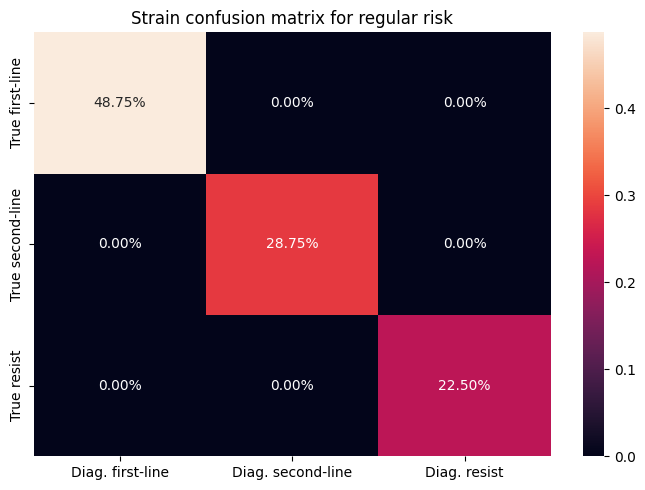

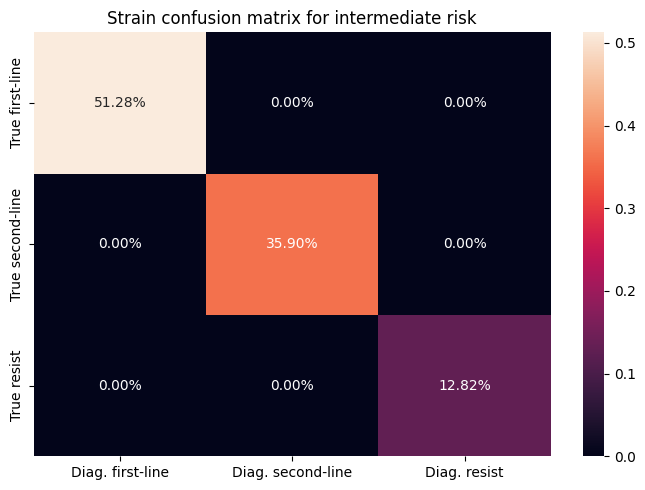

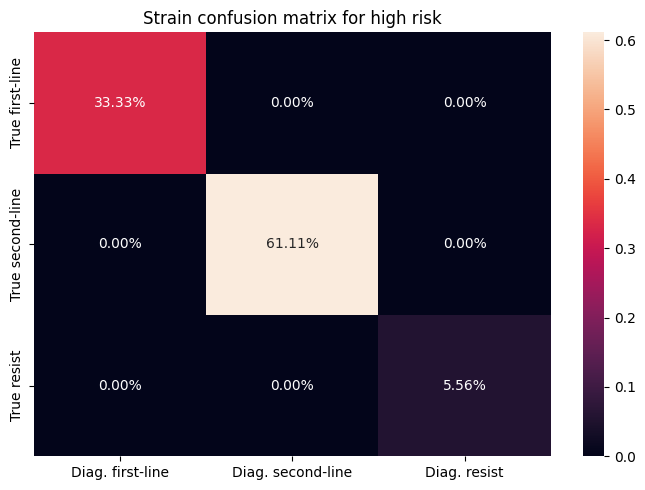

In [308]:
for i, matrix in enumerate(strain_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        normalized,
        yticklabels=["True first-line", "True second-line", "True resist"],
        xticklabels=["Diag. first-line", "Diag. second-line", "Diag. resist"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"Strain confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

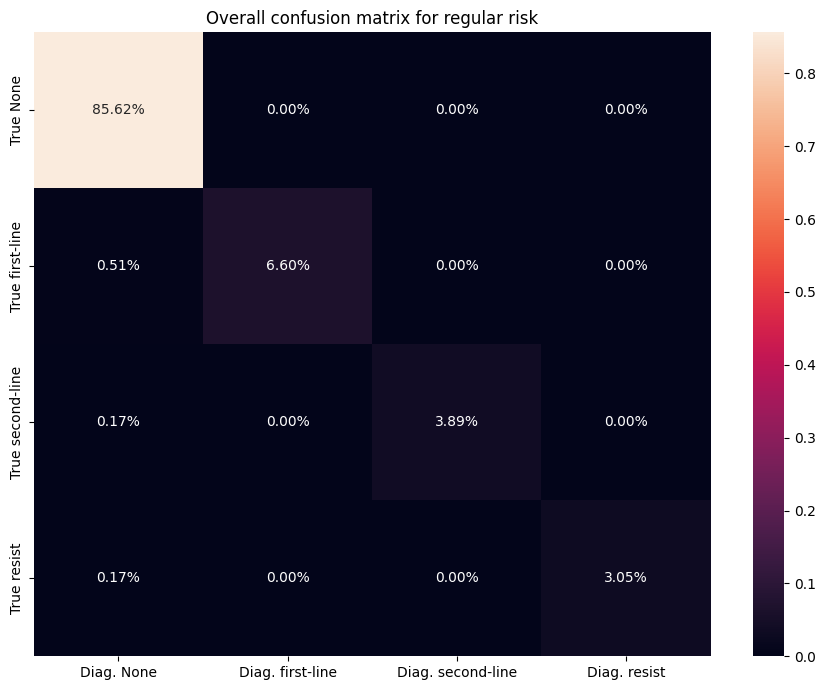

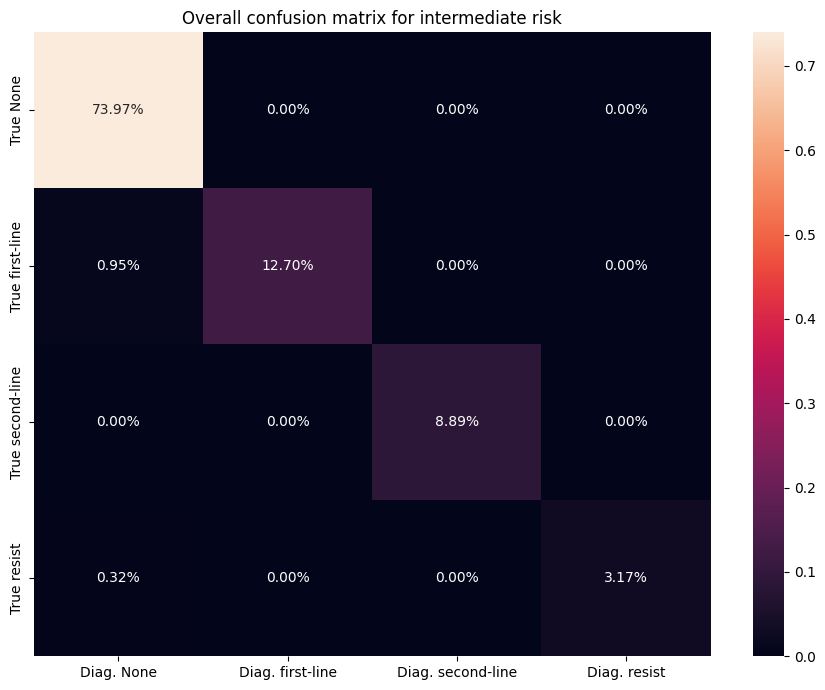

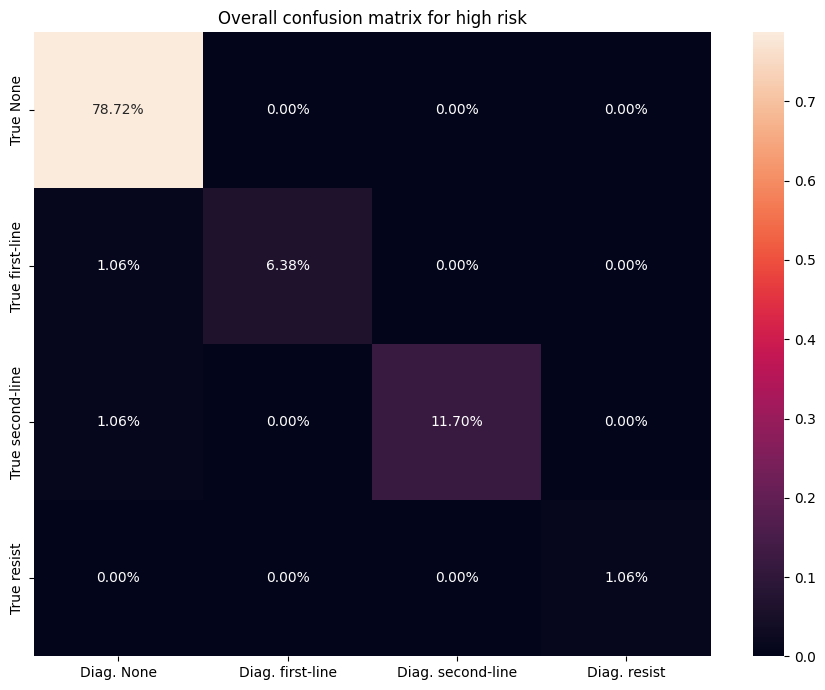

In [309]:
for i, matrix in enumerate(overall_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        normalized,
        yticklabels=["True None", "True first-line", "True second-line", "True resist"],
        xticklabels=["Diag. None", "Diag. first-line", "Diag. second-line", "Diag. resist"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"Overall confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

In [310]:
# define the costs of each treatment strategy
qaly_lambda = cfg["qaly_lambda"]
treatment_delays = cfg["treatment_delays"]
diagnostic_costs = {"clinical": 0, "dipstick": 5, "urine_culture": 8, "rapid_test": 15, "rapid_plus_ast": 35}
total_diagnostic_costs = {x: treatment_delays[x]*qaly_lambda + diagnostic_costs[x] for x in treatment_delays.keys()}
print(total_diagnostic_costs)

{'clinical': 0, 'dipstick': 5.5, 'urine_culture': 18, 'rapid_test': 15.5, 'rapid_plus_ast': 50}


In [311]:
# define the costs of successfully treating each strain, including the "null strain"
strain_treatments_financial = np.array(cfg["strain_treatments_financial"])  # should include cost of adverse events
adverse_event_prob = np.array(cfg["adverse_event_prob"])
adverse_event_cost = cfg["adverse_event_cost"]
strain_treatments = strain_treatments_financial + adverse_event_cost*adverse_event_prob
def strain_to_idx(uti_strain):
    if uti_strain is None:
        return 0
    else:
        return uti_strain+1

In [312]:
# create cost matrix from confusion matrix, only accounts for actual treatments and diagnostic strategy
cost_matrix = np.zeros((1+len(true_strain_probs),1+len(true_strain_probs)))
resolution_delay = cfg["resolution_delay"]
extra_diag = cfg["extra_diag"]
hospitalization_prob = cfg["hospitalization_prob"]
hospitalization_cost = cfg["hospitalization_cost"]

# cost_matrix[i,j] += (strain_treatments[i] + strain_treatments[j] + qaly_lambda*resolution_delay + extra_diag)

# when correct cause is identified, only cost is due to using correct treatment
for i in range(0, 1+len(true_strain_probs)):
    cost_matrix[i,i] += strain_treatments[i]
    # use stronger treatment than necessary
    for j in range(i+1,1+len(true_strain_probs)):
        cost_matrix[i,j] += strain_treatments[j]  # treatment is strong enough immediately, but pay higher price and could have adverse reaction
    # treatments are too weak
    for j in range(0,i):
        cost_matrix[i,j] += np.sum(strain_treatments[j:i+1]) + qaly_lambda*resolution_delay*(i-j) + extra_diag + hospitalization_prob[i]*hospitalization_cost  # use each intermediate treatment, plus a delay for each upgrade and consultation fees
print(cost_matrix)

[[  0.    5.2  10.4  51. ]
 [ 41.2   5.2  10.4  51. ]
 [ 67.6  52.6  10.4  51. ]
 [136.6 121.6 101.4  51. ]]


In [313]:
expected_diagnostic_outcomes = {}
for diag_strategy in all_strategies:
    risk_group_costs = [np.sum(cost_matrix*conf_mat_dict[diag_strategy]["overall"][i]) for i in range(0,3)]
    expected_diagnostic_outcomes[diag_strategy] = risk_group_costs

print(np.vstack([np.array(expected_diagnostic_outcomes[x])+total_diagnostic_costs[x] for x in all_strategies]))

[[12.63079526 16.77587302 14.19361702]
 [13.6285956  17.29365079 14.4787234 ]
 [24.22030457 27.91047619 27.3893617 ]
 [21.77106599 24.96984127 21.74468085]
 [52.85583756 54.02984127 53.24893617]]
